# Hypothesis Test — Is the shortage a *timing* problem or a *fleet-size* problem?

**CEO's question:** riders can't find bikes, yet bikes sit unused. Should we buy more bikes?

Both complaints can be true at once only if demand is very **uneven in time**: too few bikes in a few hours, too many in the rest.

### Hypothesis
> **H1:** On working days, average hourly demand in the commute peaks (7–9 am and 5–7 pm) is **more than twice** the demand in the midday hours (10 am–4 pm).
> **H0:** The peak-to-midday ratio is 2 or less.

**Why this matters:** if H1 holds, a fleet big enough for the peak must sit largely idle for most of the day. Buying more bikes raises idle bikes further; moving bikes (rebalancing) or shifting demand (pricing) attacks the real problem.

### Test design
- **Unit of analysis = one working day** (not one hour). Hours inside a day are strongly linked, so treating 17k hours as independent would overstate confidence.
- For each working day: `ratio = mean(cnt in peak hours) / mean(cnt in midday hours)`.
- **One-sided Wilcoxon signed-rank test** on `log(ratio) − log(2)` (no normality assumption).
- **Bootstrap 95% CI** of the median ratio (resampling days).
- **Control group:** weekends/holidays — there is no commute, so the peak pattern should disappear there.
- **Robustness:** repeat by year, season and weather.

**Pass criterion (set before looking):** p < 0.05 **and** the lower bound of the 95% CI is above 2.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_csv('hour.csv', parse_dates=['dteday'])
PEAK = [7, 8, 17, 18]            # 7-9 am and 5-7 pm
MIDDAY = [10, 11, 12, 13, 14, 15]  # 10 am - 4 pm

def daily_ratios(data):
    peak = data[data.hr.isin(PEAK)].groupby('dteday').cnt.mean()
    mid = data[data.hr.isin(MIDDAY)].groupby('dteday').cnt.mean()
    both = pd.concat([peak, mid], axis=1, keys=['peak', 'midday']).dropna()
    both['ratio'] = both.peak / both.midday
    return both

work = daily_ratios(df[df.workingday == 1])
off = daily_ratios(df[df.workingday == 0])
print(f'Working days analysed: {len(work)},  non-working days: {len(off)}')

Working days analysed: 498,  non-working days: 231


## 1. Look at the pattern first

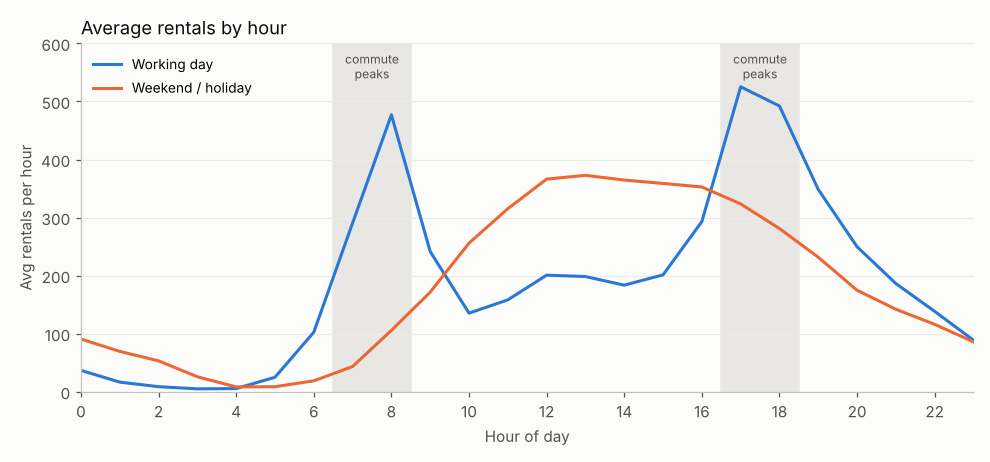

In [2]:
prof = df.groupby(['workingday', 'hr']).cnt.mean().unstack(0)
fig, ax = plt.subplots(figsize=(9, 4.2))
fig.patch.set_facecolor('#fcfcfb'); ax.set_facecolor('#fcfcfb')
ax.axvspan(6.5, 8.5, color='#e8e7e3', zorder=0); ax.axvspan(16.5, 18.5, color='#e8e7e3', zorder=0)
ax.plot(prof.index, prof[1], color='#2a78d6', lw=2, label='Working day')
ax.plot(prof.index, prof[0], color='#eb6834', lw=2, label='Weekend / holiday')
ax.text(7.5, 540, 'commute\npeaks', ha='center', fontsize=8, color='#52514e')
ax.text(17.5, 540, 'commute\npeaks', ha='center', fontsize=8, color='#52514e')
ax.set_xticks(range(0, 24, 2)); ax.set_xlim(0, 23); ax.set_ylim(0, 600)
ax.set_xlabel('Hour of day', color='#52514e'); ax.set_ylabel('Avg rentals per hour', color='#52514e')
ax.set_title('Average rentals by hour', loc='left', fontsize=12, color='#0b0b0b')
for s in ['top', 'right']: ax.spines[s].set_visible(False)
for s in ['left', 'bottom']: ax.spines[s].set_color('#c3c2b7')
ax.tick_params(colors='#52514e'); ax.grid(axis='y', color='#ecebe7', lw=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()

## 2. The test

In [3]:
log_diff = np.log(work.ratio) - np.log(2)
w = stats.wilcoxon(log_diff, alternative='greater')

rng = np.random.default_rng(42)
boot = [np.median(rng.choice(work.ratio.values, len(work))) for _ in range(5000)]
lo, hi = np.percentile(boot, [2.5, 97.5])

print(f'Median peak/midday ratio (working days): {work.ratio.median():.2f}x')
print(f'Bootstrap 95% CI of median ratio:        {lo:.2f}x  to  {hi:.2f}x')
print(f'Share of working days with ratio > 2:    {(work.ratio > 2).mean():.0%}')
print(f'Wilcoxon one-sided p-value (H0: ratio <= 2): {w.pvalue:.2e}')
print('\nRESULT:', 'Reject H0 -> peaks are more than 2x midday demand' if (w.pvalue < 0.05 and lo > 2) else 'Cannot reject H0')

Median peak/midday ratio (working days): 2.62x
Bootstrap 95% CI of median ratio:        2.58x  to  2.65x
Share of working days with ratio > 2:    85%
Wilcoxon one-sided p-value (H0: ratio <= 2): 6.94e-52

RESULT: Reject H0 -> peaks are more than 2x midday demand


## 3. Control group — weekends and holidays (no commute)

In [4]:
print(f'Median ratio on non-working days: {off.ratio.median():.2f}x')
u = stats.mannwhitneyu(work.ratio, off.ratio, alternative='greater')
print(f'Working vs non-working ratio, Mann-Whitney p = {u.pvalue:.2e}')
print('-> The peak only exists when people commute, so it is caused by commuting, not by general popularity.')

Median ratio on non-working days: 0.54x
Working vs non-working ratio, Mann-Whitney p = 1.64e-102
-> The peak only exists when people commute, so it is caused by commuting, not by general popularity.


## 4. Robustness — does it hold everywhere?

In [5]:
work = work.join(df.groupby('dteday')[['yr', 'season', 'weathersit']].agg(lambda s: s.mode()[0]))
seasons = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather = {1: 'Clear', 2: 'Mist', 3: 'Light rain/snow', 4: 'Heavy rain'}
rows = []
for name, col, labels in [('Year', 'yr', {0: '2011', 1: '2012'}), ('Season', 'season', seasons), ('Weather (day)', 'weathersit', weather)]:
    for k, g in work.groupby(col):
        rows.append([name, labels[k], len(g), round(g.ratio.median(), 2), f'{(g.ratio > 2).mean():.0%}'])
print(pd.DataFrame(rows, columns=['Split', 'Group', 'Days', 'Median ratio', '% days > 2x']).to_string(index=False))

        Split           Group  Days  Median ratio % days > 2x
         Year            2011   249          2.59         85%
         Year            2012   249          2.64         84%
       Season          Spring   119          2.55         86%
       Season          Summer   128          2.57         83%
       Season            Fall   131          2.73         89%
       Season          Winter   120          2.62         82%
Weather (day)           Clear   366          2.61         87%
Weather (day)            Mist   106          2.63         82%
Weather (day) Light rain/snow    26          2.87         69%


## 5. What it means for fleet size (the "idle bikes" side)
If the fleet is sized to cover each working day's busiest hour, how much of that fleet is actually in use during an average daytime hour?

In [6]:
wd = df[df.workingday == 1]
day_peak = wd.groupby('dteday').cnt.transform('max')
daytime = wd[wd.hr.between(7, 21)]
util = (daytime.cnt / day_peak[daytime.index])
print(f'Average daytime hour uses {util.mean():.0%} of that day\'s peak demand')
print(f'Daytime hours using less than half of the peak: {(util < 0.5).mean():.0%}')

Average daytime hour uses 50% of that day's peak demand
Daytime hours using less than half of the peak: 61%


## Conclusion
- **H0 rejected.** On working days, commute-peak demand is far more than double midday demand, and the result holds in both years, every season and every weather type.
- The control group (weekends) shows no such peak, so the cause is **commuting**.
- A fleet sized for the peak is under half used for most daytime hours — this explains *both* complaints at once.
- **Recommendation:** don't buy bikes first. Fix *timing and location*: rebalance bikes to commute origins before 7 am and 4 pm, and use off-peak pricing to spread demand. Revisit fleet size only if shortages remain after that.

### Limitations (be ready to be asked)
1. `cnt` counts **completed** rentals. When no bike is available, the lost demand is not recorded, so true peak demand is likely **even higher** than measured (this strengthens the conclusion).
2. The data has **no station or location** information and **no fleet size**, so the *where* part (bikes stuck in the wrong places) cannot be tested here.

### Next experiment (needs station data)
**Rebalancing pilot:** randomly assign comparable stations to *treatment* (trucks move bikes there before peaks) or *control* (no change) for 4 weeks. Measure **minutes a station is empty during peaks** and complaints. Compare with difference-in-differences against the weeks before the pilot. If empty-minutes drop significantly without adding bikes, the fleet is big enough.